# 07b — Ablation studies: data augmentation and the stripe shortcut

**Input:** `../data/processed/raddar.npz`, shared code `../src/dl_utils.py`
**Output:** results in `../results/`, figures in `../figures/`

**The problem (steps 4–6).** 86% of the People maps contain a strong vertical stripe that is almost never present for Cars and Drones. Grad-CAM, occlusion and attention weights showed that the CNN, the LSTM and the Transformer use these stripes to recognise people: a **shortcut**. Cropping the map removes it, but also removes real information around the target.

**Idea of this notebook.** Keep the full map, but change the **training data** so that the shortcut stops working:

| Model | Training data | Purpose |
|---|---|---|
| **Reference** | original maps | the CNN of step 4 |
| **Noise + gain augmentation** | random gain offset (±5 dB) and pixel noise (σ = 2 dB) added to each training map | classical augmentation: the EDA showed that sessions have different noise levels |
| **Synthetic stripes augmentation** | a fake stripe is added to 50% of the training maps **of all classes** | if cars and drones also have stripes, "stripe ⇒ People" is no longer a valid rule |
| **No batch norm + synthetic stripes** | same as the previous line, CNN **without batch normalisation** | combines the best result of notebook 07a with the best result of this one: candidate final model |

Same CNN, same hyperparameters, 3 seeds each. For the first three models only the training data changes (validation and test maps are never augmented).

**Three tests of the shortcut**, in addition to the usual test accuracy:
1. **Stripe injection:** add a synthetic stripe to every Car and Drone test map. How many are now predicted as People?
2. **Stripe removal:** replace the real stripes of the People test maps by noise copied from the same map. Are people still recognised?
3. **Grad-CAM:** where does the model look for People maps with a stripe?

*Run time: about 45 minutes on a laptop CPU.*

In [1]:
import sys, time, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

sys.path.append("../src")
from dl_utils import load_data, evaluate, CENTER_DOPPLER

import keras
from keras import layers

SEEDS = [42, 7, 2026]
FIG = Path("../figures"); FIG.mkdir(parents=True, exist_ok=True)
RES = Path("../results"); RES.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")

D = load_data()
X, y, CLASSES = D["X"], D["y"], D["class_names"]            # X in dB, not normalised
tr, va, te = D["train"], D["val"], D["test"]
MU, SD = X[tr].mean(), X[tr].std()
norm = lambda Xdb: ((Xdb - MU) / SD)[..., None].astype("float32")   # same normalisation as before
OUTSIDE = np.r_[0:24, 37:61]                                  # Doppler bins outside the central region
print(f"Normalisation: mean {MU:.1f} dB, std {SD:.1f} dB")

Normalisation: mean -112.1 dB, std 9.5 dB


## 1. Stripe tools: detect, add, remove
**What a real stripe looks like** (measured on the 6,161 maps that have one): one stripe per map, a peak 20–45 dB above the noise at one Doppler bin, the two neighbouring bins about 6 dB lower, then nothing (−26 dB two bins away), and about ±5 dB of variation along range. This is the shape of a **single Doppler tone** seen through the FFT window — consistent with an interference or a strong reflector at constant velocity.

- `has_stripe`: the detector of the EDA (a Doppler bin outside the centre where all 11 range bins are > 10 dB above the noise).
- `add_stripes`: draws a synthetic stripe with the measured shape at a random position outside the centre.
- `remove_stripes`: replaces the stripe columns by other (stripe-free) columns of the same map, i.e. real noise from the same recording.

In [2]:
def noise_level(Xdb):
    return np.median(Xdb.reshape(len(Xdb), -1), axis=1)

def stripe_columns(Xdb):
    rel_min = Xdb.min(axis=1) - noise_level(Xdb)[:, None]          # (n, 61)
    cols = np.zeros(rel_min.shape, dtype=bool)
    cols[:, OUTSIDE] = rel_min[:, OUTSIDE] > 10
    return cols

def has_stripe(Xdb):
    return stripe_columns(Xdb).any(axis=1)

def add_stripes(Xdb, rng, p=1.0):
    Xa = Xdb.copy()
    chosen = np.flatnonzero(rng.random(len(Xa)) < p)
    nl = noise_level(Xa[chosen])
    for i, n0 in zip(chosen, nl):
        c = rng.choice(np.r_[1:23, 38:60])                         # stripe centre, away from the target
        a = rng.uniform(20, 45)                                    # peak above noise (dB)
        profile = np.array([a - rng.normal(6, 1.5), a, a - rng.normal(6, 1.5)])
        stripe = n0 + profile[None, :] + rng.normal(0, 5, size=(Xa.shape[1], 3))
        Xa[i, :, c - 1:c + 2] = np.maximum(Xa[i, :, c - 1:c + 2], stripe)
    return Xa

def remove_stripes(Xdb, rng):
    Xr = Xdb.copy()
    cols = stripe_columns(Xdb)
    for i in np.flatnonzero(cols.any(axis=1)):
        bad = cols[i] | np.roll(cols[i], 1) | np.roll(cols[i], -1) | np.roll(cols[i], 2) | np.roll(cols[i], -2)
        bad[CENTER_DOPPLER] = False                                # never touch the target region
        donors = np.setdiff1d(OUTSIDE, np.flatnonzero(bad))
        for c in np.flatnonzero(bad):
            if len(donors):
                Xr[i, :, c] = Xdb[i, rng.permutation(Xdb.shape[1]), rng.choice(donors)]
            else:
                Xr[i, :, c] = noise_level(Xdb[i:i + 1])[0] + rng.normal(0, 5, Xdb.shape[1])
    return Xr

def augment_noise(Xdb, rng):
    return Xdb + rng.uniform(-5, 5, size=(len(Xdb), 1, 1)) + rng.normal(0, 2, size=Xdb.shape)

# Fixed modified test sets, shared by all models
rng0 = np.random.default_rng(0)
cd = te[y[te] != CLASSES.index("People")]                         # Car and Drone test maps
X_inject = add_stripes(X[cd], rng0, p=1.0)
ps = te[(y[te] == CLASSES.index("People")) & has_stripe(X[te])]   # People test maps with a real stripe
X_removed = remove_stripes(X[ps], rng0)
print(f"Injection test: {len(cd)} Car/Drone test maps; detector flags {has_stripe(X_inject).mean():.0%} of them after injection "
      f"(before: {has_stripe(X[cd]).mean():.1%})")
print(f"Removal test:   {len(ps)} People test maps with a stripe; detector flags {has_stripe(X_removed).mean():.1%} after removal")

Injection test: 1456 Car/Drone test maps; detector flags 99% of them after injection (before: 0.3%)
Removal test:   757 People test maps with a stripe; detector flags 0.0% after removal


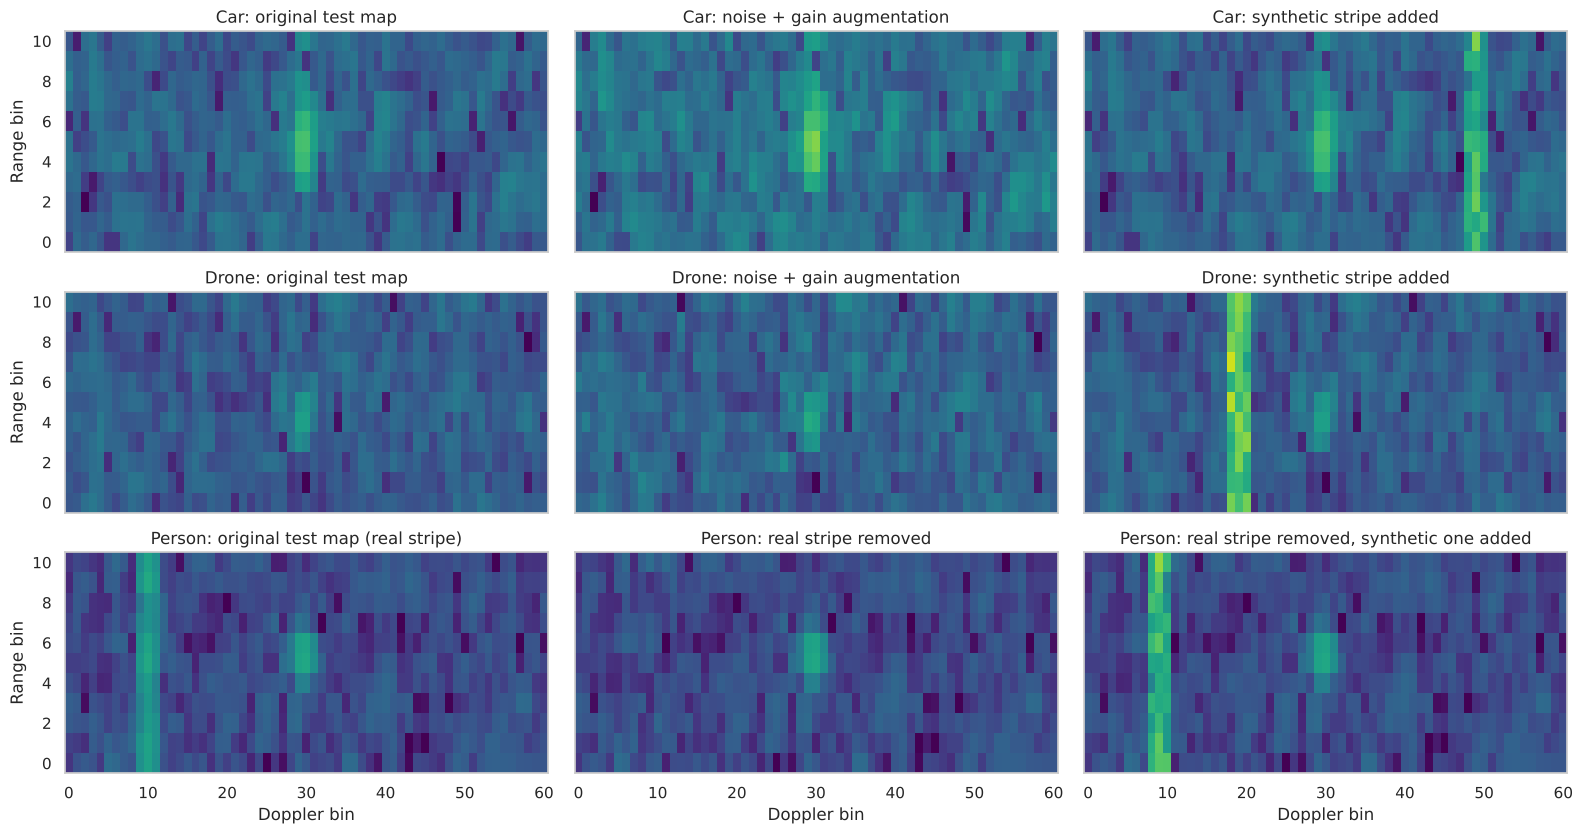

In [3]:
rng = np.random.default_rng(1)
car = rng.choice(te[(y[te] == 0) & ~has_stripe(X[te])]); drone = rng.choice(te[(y[te] == 1) & ~has_stripe(X[te])])
person = ps[5]
rows = [("Car", X[car:car + 1]), ("Drone", X[drone:drone + 1])]
fig, axes = plt.subplots(3, 3, figsize=(16, 8.5), sharex=True, sharey=True)
kw = dict(aspect="auto", origin="lower", cmap="viridis", vmin=-135, vmax=-60)
for r, (name, x) in enumerate(rows):
    axes[r, 0].imshow(x[0], **kw); axes[r, 0].set_title(f"{name}: original test map")
    axes[r, 1].imshow(augment_noise(x, rng)[0], **kw); axes[r, 1].set_title(f"{name}: noise + gain augmentation")
    axes[r, 2].imshow(add_stripes(x, rng)[0], **kw); axes[r, 2].set_title(f"{name}: synthetic stripe added")
axes[2, 0].imshow(X[person], **kw); axes[2, 0].set_title("Person: original test map (real stripe)")
axes[2, 1].imshow(X_removed[5], **kw); axes[2, 1].set_title("Person: real stripe removed")
axes[2, 2].imshow(add_stripes(X_removed[5:6], rng)[0], **kw); axes[2, 2].set_title("Person: real stripe removed, synthetic one added")
for ax in axes.ravel(): ax.grid(False)
for ax in axes[:, 0]: ax.set_ylabel("Range bin")
for ax in axes[-1]: ax.set_xlabel("Doppler bin")
plt.tight_layout(); plt.savefig(FIG / "dl_28_augmentation_examples.png", dpi=200); plt.show()

## 2. Model, augmented training data and Grad-CAM
- The CNN is exactly the reference of step 4 (`batch_norm=False` removes the batch-normalisation layers, as in notebook 07a).
- `MapDataset` builds the training batches. The augmentation is applied **on the fly**: every epoch, each map receives a new random noise / a new random stripe, so the network never sees exactly the same augmented map twice.
- Validation and test maps are never augmented.

In [4]:
def build_cnn(input_shape=(11, 61, 1), n_classes=3, dropout=0.3, batch_norm=True):
    inp = keras.Input(input_shape); x = inp
    for i, (f, pool) in enumerate(zip((32, 64, 64), [(1, 2), (2, 2), None]), start=1):
        x = layers.Conv2D(f, 3, padding="same")(x)
        if batch_norm:
            x = layers.BatchNormalization()(x)
        x = layers.ReLU(name="last_conv" if i == 3 else None)(x)
        if pool:
            x = layers.MaxPooling2D(pool)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(dropout)(x)
    return keras.Model(inp, layers.Dense(n_classes, activation="softmax")(x))


class MapDataset(keras.utils.PyDataset):
    """Training batches with on-the-fly augmentation. mode: None, 'noise' or 'stripes'."""
    def __init__(self, idx, mode, seed, batch_size=128, **kw):
        super().__init__(**kw)
        self.idx, self.mode, self.bs = np.asarray(idx), mode, batch_size
        self.rng = np.random.default_rng(seed)
        self.order = self.rng.permutation(len(self.idx))

    def __len__(self):
        return int(np.ceil(len(self.idx) / self.bs))

    def __getitem__(self, i):
        b = self.idx[self.order[i * self.bs:(i + 1) * self.bs]]
        xb = X[b]
        if self.mode == "noise":
            xb = augment_noise(xb, self.rng)
        elif self.mode == "stripes":
            xb = add_stripes(xb, self.rng, p=0.5)
        return norm(xb), y[b]

    def on_epoch_end(self):
        self.order = self.rng.permutation(len(self.idx))


def train(model, mode, seed, epochs=100):
    keras.utils.set_random_seed(seed)
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
    t0 = time.time()
    h = model.fit(MapDataset(tr, mode, seed), validation_data=(norm(X[va]), y[va]), epochs=epochs,
                  callbacks=[stop], verbose=0)
    return h.history, time.time() - t0


def grad_cam(model, Xb, class_idx, layer="last_conv"):
    grad_model = keras.Model(model.inputs, [model.get_layer(layer).output, model.output])
    Xb = tf.convert_to_tensor(Xb)
    with tf.GradientTape() as tape:
        conv, out = grad_model(Xb, training=False)
        score = tf.gather(out, class_idx, axis=1, batch_dims=1)
    grads = tape.gradient(score, conv)
    cam = tf.nn.relu(tf.reduce_sum(tf.reduce_mean(grads, axis=(1, 2), keepdims=True) * conv, axis=-1))[..., None]
    cam = tf.image.resize(cam, Xb.shape[1:3]).numpy()[..., 0]
    return cam / (cam.reshape(len(cam), -1).max(1)[:, None, None] + 1e-9)


# Position of the real stripe in each People test map that has one (strongest stripe column)
stripe_centre = OUTSIDE[np.argmax((X[ps].min(axis=1) - noise_level(X[ps])[:, None])[:, OUTSIDE], axis=1)]
OFFSETS = np.arange(-8, 9)

def stripe_attention(cam, centres):
    """Share of the Grad-CAM on the stripe (3 columns) and attention profile centred on the stripe."""
    total = cam.sum(axis=(1, 2)) + 1e-9
    share = np.mean([cam[i][:, max(c - 1, 0):c + 2].sum() / total[i] for i, c in enumerate(centres)])
    col = cam.mean(axis=1)                                   # attention per Doppler bin
    col = col / (col.mean(axis=1, keepdims=True) + 1e-9)     # 1 = average attention of the map
    prof = np.full((len(cam), len(OFFSETS)), np.nan)
    for j, o in enumerate(OFFSETS):
        c = centres + o
        ok = (c >= 0) & (c < cam.shape[2])
        prof[ok, j] = col[ok, c[ok]]
    return float(share), np.nanmean(prof, axis=0)

## 3. Training and shortcut tests: 4 models × 3 seeds
For each trained model:
- standard evaluation on the test sessions;
- **injection test:** share of the Car/Drone test maps predicted as People, before and after adding a synthetic stripe;
- **removal test:** recall of the People test maps that have a real stripe, before and after removing it;
- **Grad-CAM** on the People test maps with a stripe (correctly classified): mean map, share of the attention outside the central region, share of the attention on the 3 columns of the stripe (a uniform attention would give 3/61 = 4.9%), and attention profile centred on the stripe.

Each finished run is saved in `../results/dl_step7b_runs.json` and reloaded if the notebook is re-run (`FORCE_RETRAIN = True` to train again).

In [5]:
MODELS = {"Reference": (None, True), "Noise + gain augmentation": ("noise", True),          # name: (augmentation, batch norm)
          "Synthetic stripes augmentation": ("stripes", True), "No batch norm + synthetic stripes": ("stripes", False)}
SHORT = ["Reference", "Noise + gain\naugmentation", "Synthetic stripes\naugmentation", "No batch norm +\nsynthetic stripes"]
COLORS = ["#8d99ae", "#457b9d", "#2a9d8f", "#e9c46a"]
PEOPLE = CLASSES.index("People")
RUNS_FILE = RES / "dl_step7b_runs.json"
FORCE_RETRAIN = False
saved = {} if (FORCE_RETRAIN or not RUNS_FILE.exists()) else json.loads(RUNS_FILE.read_text())
Xte, Xinj, Xrem, Xps = norm(X[te]), norm(X_inject), norm(X_removed), norm(X[ps])

runs, histories, cams, profiles = [], {}, {}, {}
for name, (mode, bn) in MODELS.items():
    for s in SEEDS:
        key = f"{name} | seed {s}"
        if key not in saved:
            keras.utils.set_random_seed(s)
            model = build_cnn(batch_norm=bn)
            h, t = train(model, mode, s)
            pred = lambda A: model.predict(A, verbose=0, batch_size=512).argmax(1)
            pt = pred(Xte)
            r = {"Model": name, "Seed": s, "Epochs": len(h["loss"]), "Best epoch": int(np.argmin(h["val_loss"])) + 1,
                 "Time (s)": t, "Val accuracy": (pred(norm(X[va])) == y[va]).mean()}
            r.update({("Test " + k): v for k, v in evaluate(y[te], pt, CLASSES).items()})
            p_cd, p_inj = pred(norm(X[cd])), pred(Xinj)
            r["Cars/Drones predicted People (original)"] = (p_cd == PEOPLE).mean()
            r["Cars/Drones predicted People (stripe injected)"] = (p_inj == PEOPLE).mean()
            r["Cars/Drones accuracy (original)"] = (p_cd == y[cd]).mean()
            r["Cars/Drones accuracy (stripe injected)"] = (p_inj == y[cd]).mean()
            p_ps, p_rem = pred(Xps), pred(Xrem)
            r["People-with-stripe recall (original)"] = (p_ps == PEOPLE).mean()
            r["People-with-stripe recall (stripe removed)"] = (p_rem == PEOPLE).mean()
            okp = np.flatnonzero(p_ps == PEOPLE)
            cam = np.concatenate([grad_cam(model, Xps[b], np.full(len(b), PEOPLE, dtype="int32"))
                                  for b in np.array_split(okp, max(1, len(okp) // 200))])
            r["Grad-CAM share outside centre (People with stripe)"] = float(
                1 - cam[:, :, CENTER_DOPPLER].sum() / cam.sum())
            r["Grad-CAM share on the stripe (People with stripe)"], profile = stripe_attention(cam, stripe_centre[okp])
            saved[key] = {"metrics": {k: (v.item() if hasattr(v, "item") else v) for k, v in r.items()},
                          "history": {k: [float(v) for v in vals] for k, vals in h.items()},
                          "mean_cam": cam.mean(0).round(4).tolist(), "stripe_profile": profile.round(4).tolist()}
            RUNS_FILE.write_text(json.dumps(saved))
        r = saved[key]["metrics"]
        runs.append(r); histories[(name, s)] = saved[key]["history"]; cams[(name, s)] = np.array(saved[key]["mean_cam"])
        profiles[(name, s)] = np.array(saved[key]["stripe_profile"])
        print(f"{name:33s} | seed {s:4d} | {r['Epochs']:3d} epochs | test acc {r['Test accuracy']:.3f} | "
              f"fooled by stripe {r['Cars/Drones predicted People (stripe injected)']:.1%} | {r['Time (s)']:4.0f} s")

runs = pd.DataFrame(runs)
runs.to_csv(RES / "dl_step7b_augmentation_runs.csv", index=False)

Reference                         | seed   42 |  28 epochs | test acc 0.915 | fooled by stripe 75.9% |  261 s
Reference                         | seed    7 |  21 epochs | test acc 0.957 | fooled by stripe 52.4% |  205 s
Reference                         | seed 2026 |  26 epochs | test acc 0.938 | fooled by stripe 65.1% |  267 s
Noise + gain augmentation         | seed   42 |  28 epochs | test acc 0.948 | fooled by stripe 67.5% |  274 s
Noise + gain augmentation         | seed    7 |  22 epochs | test acc 0.936 | fooled by stripe 69.0% |  232 s
Noise + gain augmentation         | seed 2026 |  28 epochs | test acc 0.951 | fooled by stripe 63.5% |  278 s
Synthetic stripes augmentation    | seed   42 |  17 epochs | test acc 0.944 | fooled by stripe 6.2% |  163 s
Synthetic stripes augmentation    | seed    7 |  27 epochs | test acc 0.949 | fooled by stripe 4.5% |  267 s
Synthetic stripes augmentation    | seed 2026 |  23 epochs | test acc 0.942 | fooled by stripe 3.2% |  228 s
No batch norm

## 4. Summary (mean ± std over the 3 seeds)

In [6]:
num = [c for c in runs.columns if c not in ("Model", "Seed")]
g = runs.groupby("Model", sort=False)
summary = g[num].mean()
summary.insert(summary.columns.get_loc("Test accuracy") + 1, "Test accuracy std", g["Test accuracy"].std())
summary.to_csv(RES / "dl_step7b_augmentation_summary.csv")
summary.T.round(3)

Model,Reference,Noise + gain augmentation,Synthetic stripes augmentation,No batch norm + synthetic stripes
Epochs,25.000,26.000,22.333,39.000
Best epoch,15.000,16.000,12.333,29.000
Time (s),244.155,261.291,219.242,264.777
Val accuracy,0.953,0.963,0.945,0.951
Test accuracy,0.937,0.945,0.945,0.950
Test accuracy std,0.021,0.008,0.004,0.004
Test recall Cars,0.911,0.885,0.912,0.916
Test recall Drones,0.890,0.960,0.920,0.934
Test recall People,0.994,0.986,0.993,0.991
Cars/Drones predicted People (original),0.010,0.003,0.018,0.011


## 5. Results of the three tests
- **Left:** standard test accuracy.
- **Middle — injection test:** share of Car/Drone test maps predicted as People, on the original maps and after a synthetic stripe is added. A model that relies on "stripe ⇒ People" is fooled.
- **Right — removal test:** recall of the People test maps with a real stripe, on the original maps and after the stripe is removed. A model that needs the stripe loses these people.

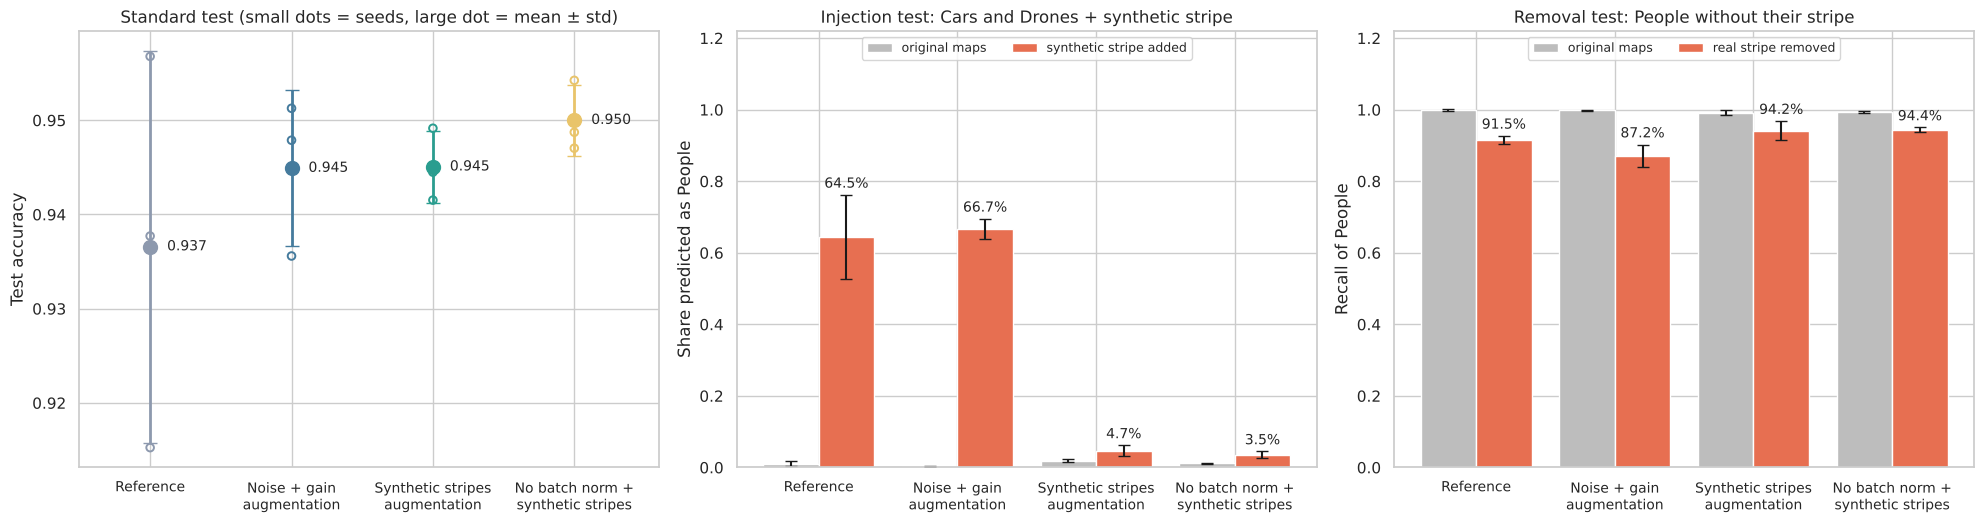

In [7]:
std = runs.groupby("Model", sort=False)[num].std()
names = list(MODELS); xpos = np.arange(len(names)); short = SHORT
fig, axes = plt.subplots(1, 3, figsize=(20, 5.4))
for xx, name, c in zip(xpos, names, COLORS):
    seeds = runs.loc[runs.Model == name, "Test accuracy"]
    axes[0].scatter([xx] * len(seeds), seeds, s=30, facecolors="none", edgecolors=c, linewidths=1.4, zorder=3)
    axes[0].errorbar(xx, seeds.mean(), yerr=seeds.std(), fmt="o", ms=10, color=c, capsize=5, lw=2, zorder=4)
    axes[0].text(xx + 0.12, seeds.mean(), f"{seeds.mean():.3f}", va="center", fontsize=10)
axes[0].set(xlim=(-0.5, len(names) - 0.4), ylabel="Test accuracy",
            title="Standard test (small dots = seeds, large dot = mean ± std)")
pairs = [(axes[1], "Cars/Drones predicted People (original)", "Cars/Drones predicted People (stripe injected)",
          "original maps", "synthetic stripe added", "Share predicted as People", "Injection test: Cars and Drones + synthetic stripe"),
         (axes[2], "People-with-stripe recall (original)", "People-with-stripe recall (stripe removed)",
          "original maps", "real stripe removed", "Recall of People", "Removal test: People without their stripe")]
for ax, a, b, la, lb, yl, title in pairs:
    ax.bar(xpos - 0.2, summary[a], 0.4, yerr=std[a], color="#bdbdbd", capsize=4, label=la)
    ax.bar(xpos + 0.2, summary[b], 0.4, yerr=std[b], color="#e76f51", capsize=4, label=lb)
    for xx, v, e in zip(xpos + 0.2, summary[b], std[b]):
        ax.text(xx, v + e + 0.02, f"{v:.1%}", ha="center", fontsize=10)
    ax.set(ylim=(0, 1.22), ylabel=yl, title=title); ax.legend(loc="upper center", ncol=2, fontsize=9)
for ax in axes:
    ax.set_xticks(xpos); ax.set_xticklabels(short, fontsize=10)
plt.tight_layout(); plt.savefig(FIG / "dl_29_augmentation_shortcut_tests.png", dpi=200); plt.show()

## 6. Grad-CAM: where does each model look for People with a stripe?
Mean Grad-CAM over the People test maps that contain a real stripe (seed 42). The white dotted lines mark the central region where the person is. The percentage is the share of the attention outside this region, averaged over the 3 seeds (a uniform attention would give 79%).

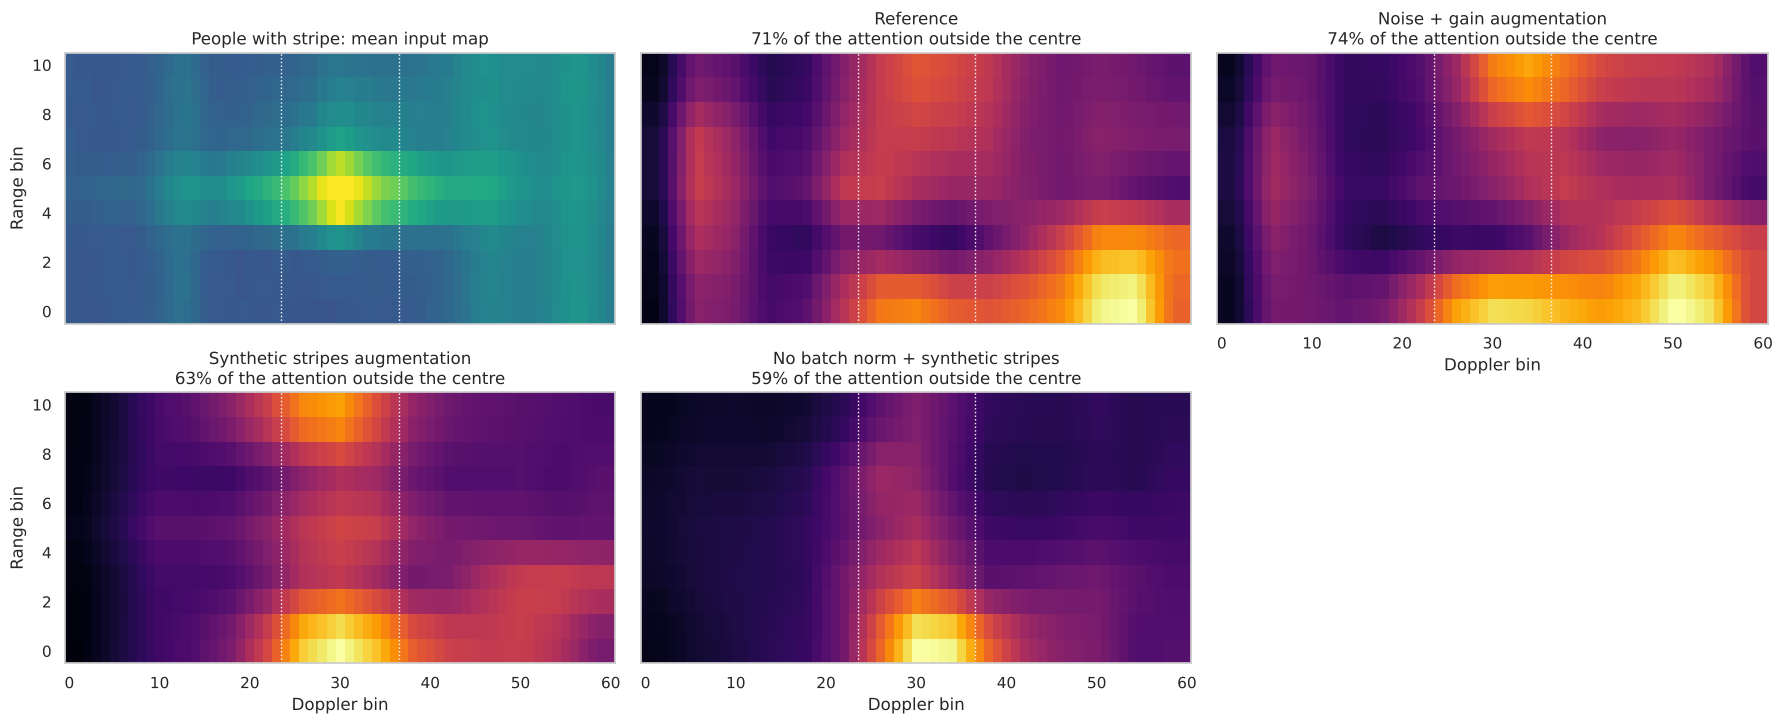

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(18, 7.4), sharex=True, sharey=True)
axes = axes.ravel()
axes[0].imshow(X[ps].mean(0), aspect="auto", origin="lower", cmap="viridis", vmin=-125, vmax=-85)
axes[0].set_title("People with stripe: mean input map")
for ax, name in zip(axes[1:], names):
    share = summary.loc[name, "Grad-CAM share outside centre (People with stripe)"]
    ax.imshow(cams[(name, SEEDS[0])], aspect="auto", origin="lower", cmap="inferno", vmin=0)
    ax.set_title(f"{name}\n{share:.0%} of the attention outside the centre")
for ax in axes[:5]:
    ax.axvline(CENTER_DOPPLER.start - 0.5, color="w", ls=":", lw=1); ax.axvline(CENTER_DOPPLER.stop - 0.5, color="w", ls=":", lw=1)
    ax.grid(False)
for ax in axes[3:5]: ax.set_xlabel("Doppler bin")
axes[2].tick_params(labelbottom=True); axes[2].set_xlabel("Doppler bin")
for ax in (axes[0], axes[3]): ax.set_ylabel("Range bin")
axes[5].axis("off")
plt.tight_layout(); plt.savefig(FIG / "dl_30_augmentation_gradcam.png", dpi=200); plt.show()

## 7. Grad-CAM centred on the stripe
The stripe is not at the same Doppler bin in every map, so it is blurred in the mean map above. Here every Grad-CAM map is **re-centred on its own stripe** before averaging: offset 0 is the stripe. The y axis is the attention relative to the average of the map (1 = same attention as everywhere else). A peak at offset 0 means that the model looks at the stripe itself.

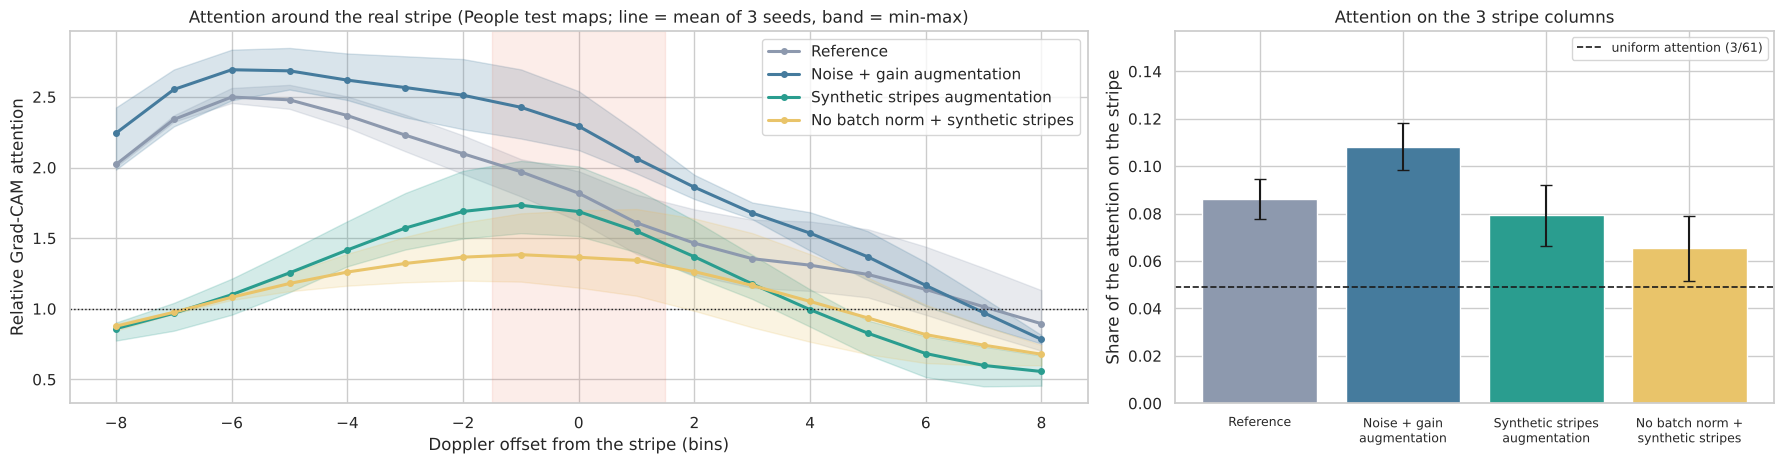

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(18, 4.8), gridspec_kw=dict(width_ratios=[1.7, 1]))
colors = COLORS
for name, c in zip(names, colors):
    P = np.array([profiles[(name, s)] for s in SEEDS])
    axes[0].plot(OFFSETS, P.mean(0), color=c, lw=2.2, marker="o", ms=4, label=name)
    axes[0].fill_between(OFFSETS, P.min(0), P.max(0), color=c, alpha=0.2)
axes[0].axhline(1, color="k", ls=":", lw=1); axes[0].axvspan(-1.5, 1.5, color="#e76f51", alpha=0.12)
axes[0].set(xlabel="Doppler offset from the stripe (bins)", ylabel="Relative Grad-CAM attention",
            title="Attention around the real stripe (People test maps; line = mean of 3 seeds, band = min-max)")
axes[0].legend()
col = "Grad-CAM share on the stripe (People with stripe)"
axes[1].bar(xpos, summary[col], yerr=std[col], color=colors, capsize=4)
axes[1].axhline(3 / 61, color="k", ls="--", lw=1.2, label="uniform attention (3/61)")
axes[1].set_xticks(xpos); axes[1].set_xticklabels(short, fontsize=9)
axes[1].set(ylim=(0, summary[col].max() * 1.45), ylabel="Share of the attention on the stripe", title="Attention on the 3 stripe columns")
axes[1].legend(loc="upper right", fontsize=9)
plt.tight_layout(); plt.savefig(FIG / "dl_31_augmentation_gradcam_stripe.png", dpi=200); plt.show()

## 8. Learning curves (validation loss, 3 seeds per model)

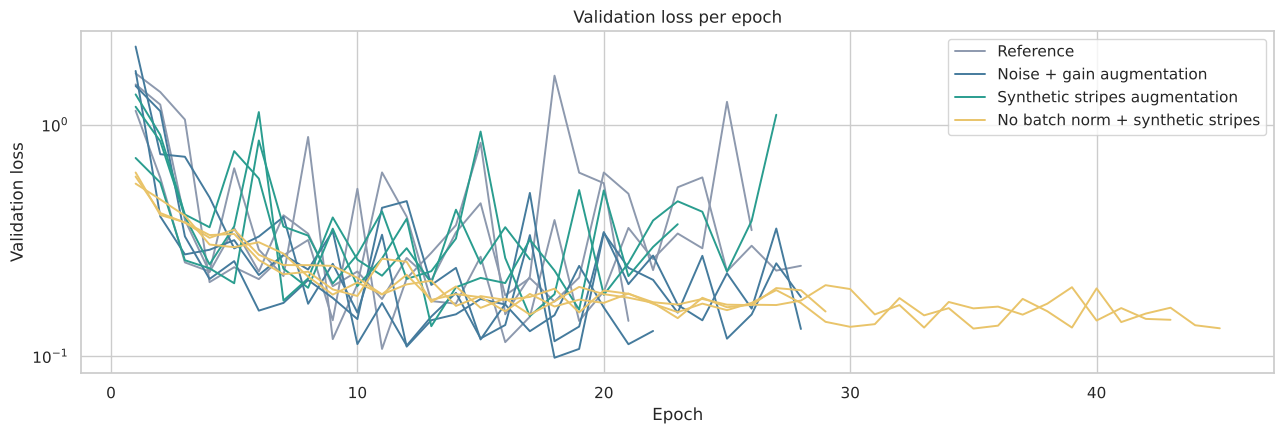

In [10]:
fig, ax = plt.subplots(figsize=(13, 4.5))
for name, c in zip(names, COLORS):
    for i, s in enumerate(SEEDS):
        vl = histories[(name, s)]["val_loss"]
        ax.plot(np.arange(1, len(vl) + 1), vl, color=c, lw=1.4, label=name if i == 0 else None)
ax.set(xlabel="Epoch", ylabel="Validation loss", yscale="log", title="Validation loss per epoch")
ax.legend()
plt.tight_layout(); plt.savefig(FIG / "dl_32_augmentation_validation_curves.png", dpi=200); plt.show()

## 9. Conclusions

1. **The stripe shortcut is now proven by an intervention, not only suggested by an explanation map.** When a synthetic stripe is added to a Car or Drone test map, the reference CNN answers "People" in **64.5%** of the cases (1.0% before), and its accuracy on Cars and Drones falls from 0.90 to 0.30. Nothing else changed in the map: the stripe alone flips the decision.
2. **A classical augmentation does not help.** With noise + gain augmentation the model is fooled just as often (66.7%). Making the model robust to noise levels does not make it robust to the stripe: the augmentation must target the shortcut itself.
3. **Synthetic stripes in all classes during training remove the shortcut.** The model is fooled in only **4.7%** of the cases, and its accuracy on Cars and Drones with a stripe stays at 0.89 (0.92 without). The standard test accuracy does not decrease (0.945 ± 0.004 against 0.937 ± 0.021): the shortcut was **not needed** to reach this accuracy.
4. **The stripe is sufficient but not necessary to recognise people.** When the real stripe is removed, the reference still recognises 91.5% of the people (99.9% with the stripe): it also uses the signature of the person in the centre. The stripe-augmented models lose a little less (94.2%).
5. **Grad-CAM is too coarse to show this change.** The attention outside the centre decreases (71% → 63% → 59%), but the share of the attention on the stripe itself is similar for all models (6–11%, against 4.9% for a uniform attention). The Grad-CAM map comes from the last convolution layer (5 × 15 cells: one cell covers 4 Doppler bins), so it cannot isolate a stripe of 3 bins. **The intervention tests (points 1–4) are the reliable evidence; the attention maps are only an indication.**
6. **Both improvements add up.** Without batch normalisation (notebook 07a) and with synthetic stripes: test accuracy **0.950 ± 0.004**, fooled in 3.5% of the cases, people recall without stripe 94.4%, and a smooth training (validation loss roughness 0.03 against 0.27 for the reference). This is the candidate final CNN.

| | Full map, reference | Cropped map (step 4) | Full map, no batch norm + synthetic stripes |
|---|---|---|---|
| Test accuracy | 0.937–0.941 | 0.923 | **0.950** |
| Fooled by a stripe | 64.5% | cannot see it | 3.5% |

Compared with cropping, the stripe augmentation keeps the information of the whole map **and** ignores the stripe.

**Observation on the reference.** The reference reaches 0.937 ± 0.021 here and 0.941 ± 0.006 in notebook 07a with the same architecture and seeds. The only difference is the order of the training batches (the data generator shuffles differently). With batch normalisation, the batch order alone changes the accuracy by as much as most ablations.

**Limits.**
- The synthetic stripes imitate the measured shape of the real ones (position, width, amplitude), but they are a model. The injection test uses the same generator as the training: a real interference on a car could look different. The removal test, which uses the **real** stripes, is the independent check.
- The removal test replaces the stripe by shuffled noise columns of the same map, which is not exactly a recording without stripe.
- 3 seeds, one split by sessions. The origin of the stripes in the dataset is still unknown.